# Exp2 — SDXL GenEval Runner (Colab)

Compares **Standard Sampling**, **Resampling (RePaint / Lugmayr 2022)**, and **Z-Sampling** on the GenEval benchmark using SDXL.

Outputs are saved directly to Google Drive so they survive session disconnections.  

## Cell 1 — Mount Google Drive and clone repo

In [ ]:
from google.colab import drive, userdata
drive.mount('/content/drive')

import subprocess, os

token = userdata.get('GITHUB_TOKEN')

REPO_DIR = "/content/generative-modelling"
BRANCH = "resampling-cleaned-up"
REMOTE = f"https://{token}@github.com/viftode4/generative-modelling.git"

if not os.path.exists(REPO_DIR):
    subprocess.run(["git", "clone", REMOTE, REPO_DIR], check=True)

subprocess.run(["git", "-C", REPO_DIR, "fetch", "origin"], check=True)
subprocess.run(["git", "-C", REPO_DIR, "checkout", BRANCH], check=True)
subprocess.run(["git", "-C", REPO_DIR, "reset", "--hard", f"origin/{BRANCH}"], check=True)

print(f"Repo ready at {REPO_DIR} on branch {BRANCH}")


Mounted at /content/drive
Repo ready at /content/generative-modelling on branch resampling-cleaned-up


## Cell 2 — Install dependencies

Uses diffusers 0.36+ (not the pinned 0.22.3 from `requirements-zigzag.txt`, which is for the upstream ZigZag code and is too old for our resampling rewrite).

In [ ]:
!pip install -q diffusers transformers accelerate safetensors tqdm pandas xformers
print("Dependencies installed.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 104.2 MB/s eta 0:00:00
Dependencies installed.


## Cell 3 — Smoke test (2 prompts)

Run this first to confirm nothing crashes before committing to the full run.

In [ ]:
# Patch: replace broken inverse_scheduler.step() with manual DDIM inversion
script_path = "/content/generative-modelling/src/zigzag_project/zsampling.py"
with open(script_path) as f:
    content = f.read()

old = """                    inv_latents = inverse_scheduler.step(
                        inverse_noise_pred,
                        timesteps[i + 1],
                        next_latents,
                        return_dict=False,
                    )[0]

                    forward_noise_pred = _guided_noise_prediction("""

new = """                    # Manual DDIM inversion: go from t[i+1] (less noisy) back to t[i] (more noisy)
                    _a_from = pipe.scheduler.alphas_cumprod[timesteps[i + 1].item()].to(next_latents.device, dtype=next_latents.dtype)
                    _a_to   = pipe.scheduler.alphas_cumprod[timesteps[i].item()].to(next_latents.device, dtype=next_latents.dtype)
                    _pred_x0 = (next_latents - (1 - _a_from).sqrt() * inverse_noise_pred) / _a_from.sqrt()
                    inv_latents = _a_to.sqrt() * _pred_x0 + (1 - _a_to).sqrt() * inverse_noise_pred

                    forward_noise_pred = _guided_noise_prediction("""

if old in content:
    content = content.replace(old, new)
    with open(script_path, "w") as f:
        f.write(content)
    print("Patched successfully.")
else:
    print("Pattern not found")
    for i, line in enumerate(content.split('\n')):
        if 'inverse_scheduler.step' in line or 'inv_latents' in line:
            print(f"Line {i+1}: {repr(line)}")


Patched successfully.


In [ ]:
import sys, os
os.chdir(REPO_DIR)
sys.path.insert(0, os.path.join(REPO_DIR, "src"))

SMOKE_OUT = "/content/drive/MyDrive/exp2_geneval_smoke"

!python scripts/run_exp2_sdxl_geneval.py \
    --test-run \
    --device cuda \
    --steps 50 \
    --cfg 5.5 \
    --out {SMOKE_OUT}

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Loading GenEval prompts from data/prompts/evaluation_metadata.jsonl...
TEST RUN: Only running the first 2 prompts.
Loading SDXL Model on CUDA...
Loading pipeline components...:   0% 0/7 [00:00<?, ?it/s]
Loading weights:   0% 0/517 [00:00<?, ?it/s]
Loading weights:   0% 2/517 [00:01<08:07,  1.06it/s]
Loading weights:  11% 56/517 [00:02<00:12, 37.38it/s]
Loading weights:  15% 77/517 [00:02<00:10, 42.29it/s]
Loading weights:  18% 91/517 [00:02<00:09, 43.26it/s]
Loading weights:  20% 102/517 [00:02<00:08, 49.82it/s]
Loading weights:  22% 113/517 [00:03<00:08, 47.67it/s]
Loading weights:  24% 122/517 [00:03<00:08, 44.22it/s]
Loading weights:  25% 130/517 [00:03<00:07, 48.93it/s]
Loading weights:  2

## Cell 4 — Verify smoke test output

2 rows in manifest


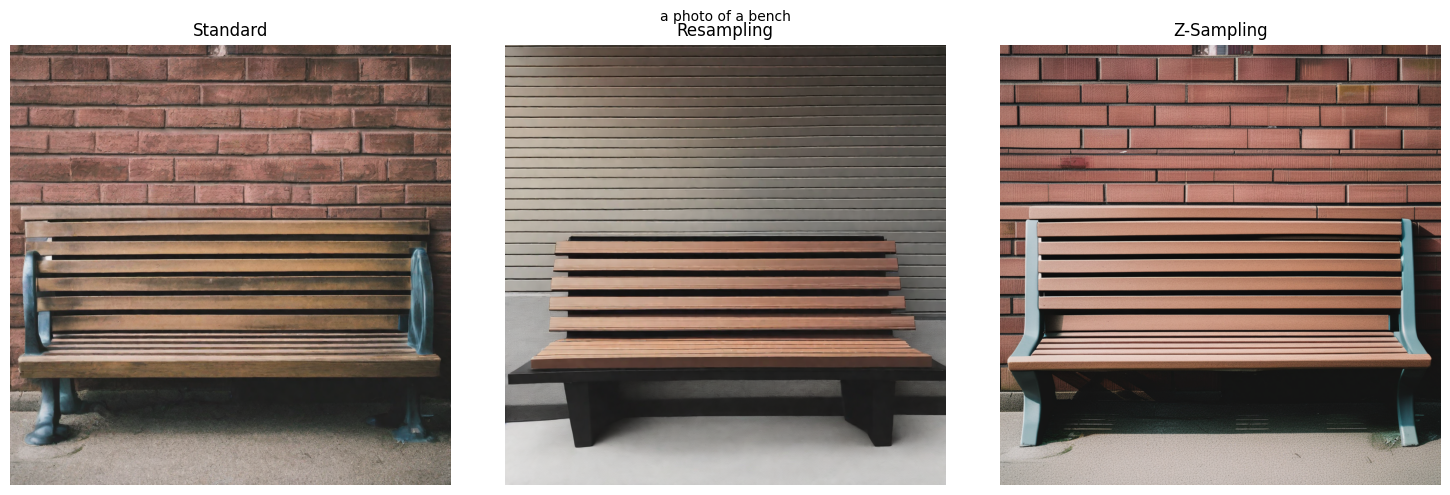

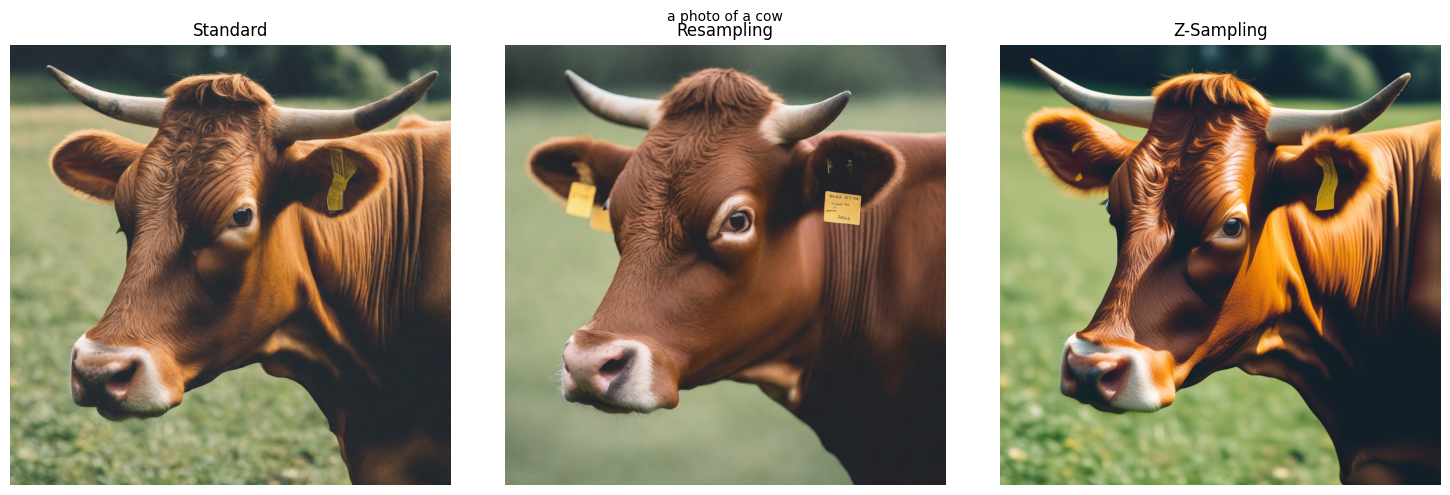

In [ ]:
import json
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

manifest_path = Path(SMOKE_OUT) / "manifest.jsonl"
rows = [json.loads(l) for l in manifest_path.read_text().splitlines()]
print(f"{len(rows)} rows in manifest")

for row in rows:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(row["prompt"], fontsize=10)
    for ax, key, label in zip(axes,
        ["standard_path", "resampling_path", "zigzag_path"],
        ["Standard", "Resampling", "Z-Sampling"]):
        ax.imshow(Image.open(row[key]))
        ax.set_title(label)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## Cell 5 — Full run (all GenEval prompts)

Saves images directly to Google Drive. If the session disconnects, re-run this cell — already-generated images will be skipped automatically.

**Estimated time:** ~12–20 h on T4 (free), ~4–6 h on A100 (Colab Pro).

In [ ]:
import os
os.chdir("/content/generative-modelling")


In [ ]:
FULL_OUT = "/content/drive/MyDrive/exp2_geneval_full"

!python scripts/run_exp2_sdxl_geneval.py \
    --device cuda \
    --steps 50 \
    --cfg 5.5 \
    --max-per-skill 5 \
    --out /content/drive/MyDrive/exp2_geneval_full


Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Loading GenEval prompts from data/prompts/evaluation_metadata.jsonl...
/content/generative-modelling/scripts/run_exp2_sdxl_geneval.py:50: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min(len(x), args.max_per_skill), random_state=42))
SUBSET: 30 prompts (5 per skill tag).
Loading SDXL Model on CUDA...
model_index.json: 100% 609/609 [00:00<00:00, 2.93MB/s]
Fetching 19 files:   0%

## Cell 6 — Check progress after a session resumes

In [ ]:
import os
os.makedirs("/content/geneval_weights", exist_ok=True)
!wget -q https://download.openmmlab.com/mmdetection/v2.0/mask2former/mask2former_swin-s-p4-w7-224_lsj_8x2_50e_coco/mask2former_swin-s-p4-w7-224_lsj_8x2_50e_coco_20220504_001756-743b7d99.pth \
    -O /content/geneval_weights/mask2former_swin-s-p4-w7-224_lsj_8x2_50e_coco.pth


## Evaluation for the Results using original Geneval paper

In [ ]:
!pip install -q ultralytics open-clip-torch clip-benchmark


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 57.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 71.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 82.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.0/75.0 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.3/104.3 MB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.7/310.7 kB 24.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
openxlab 0.1.3 requires rich~=13.4.2, but you have rich 15.0.0 which is incompatible.
pyiceberg 0.11.1 requires rich<15.0.0,>=10.11.0, but you have rich 15.0.0 which is incompatible.
bigframes 2.42

In [ ]:
import json, shutil
from pathlib import Path

MANIFEST = "/content/drive/MyDrive/exp2_geneval_full/manifest.jsonl"
PROMPTS  = "/content/generative-modelling/data/prompts/evaluation_metadata.jsonl"
EVAL_BASE = "/content/drive/MyDrive/exp2_geneval_eval"

meta_lookup = {r["prompt"]: r for r in
               [json.loads(l) for l in Path(PROMPTS).read_text().splitlines() if l.strip()]}
rows = [json.loads(l) for l in Path(MANIFEST).read_text().splitlines() if l.strip()]

for method, key in [("standard","standard_path"),("resampling","resampling_path"),("zigzag","zigzag_path")]:
    print(f"Reorganizing {method}...")
    for row in rows:
        meta = meta_lookup.get(row["prompt"])
        if not meta: continue
        idx = int(row["prompt_id"].split("_")[1])
        dest = Path(EVAL_BASE) / method / str(idx)
        (dest / "samples").mkdir(parents=True, exist_ok=True)
        (dest / "metadata.jsonl").write_text(json.dumps(meta))
        shutil.copy2(row[key], dest / "samples" / "0.png")
    print(f"  Done.")
print("All methods reorganized.")


Reorganizing standard...
  Done.
Reorganizing resampling...
  Done.
Reorganizing zigzag...
  Done.
All methods reorganized.


In [ ]:
import json, os, re, warnings
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image, ImageOps
import torch
warnings.filterwarnings("ignore")

from ultralytics import YOLO
import open_clip
from clip_benchmark.metrics import zeroshot_classification as zsc
zsc.tqdm = lambda it, *args, **kwargs: it

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Load models
yolo_model = YOLO("yolov8m.pt")
YOLO_CLASSES = yolo_model.names

clip_model, _, transform = open_clip.create_model_and_transforms("ViT-L-14", pretrained="openai", device=DEVICE)
tokenizer = open_clip.get_tokenizer("ViT-L-14")

with open("/content/geneval/evaluation/object_names.txt") as f:
    classnames = [line.strip() for line in f]

classname_to_yolo_idx = {v: k for k, v in YOLO_CLASSES.items()}

def run_detector(filepath):
    results = yolo_model(filepath, verbose=False)[0]
    boxes = results.boxes
    bbox = []
    for classname in classnames:
        idx = classname_to_yolo_idx.get(classname, -1)
        if idx == -1 or boxes is None:
            bbox.append(np.zeros((0, 5), dtype=np.float32))
            continue
        mask = (boxes.cls.cpu().numpy().astype(int) == idx)
        if not mask.any():
            bbox.append(np.zeros((0, 5), dtype=np.float32))
        else:
            xyxy = boxes.xyxy.cpu().numpy()[mask]
            conf = boxes.conf.cpu().numpy()[mask, None]
            bbox.append(np.hstack([xyxy, conf]).astype(np.float32))
    return bbox

# Color classification
COLORS = ["red", "orange", "yellow", "green", "blue", "purple", "pink", "brown", "black", "white"]
COLOR_CLASSIFIERS = {}

class ImageCrops(torch.utils.data.Dataset):
    def __init__(self, image, objects):
        self._image = image.convert("RGB")
        self._blank = Image.new("RGB", image.size, color="#999")
        self._objects = objects
    def __len__(self): return len(self._objects)
    def __getitem__(self, index):
        box, _ = self._objects[index]
        image = self._image.crop(box[:4])
        return (transform(image), 0)

def color_classification(image, bboxes, classname):
    if classname not in COLOR_CLASSIFIERS:
        COLOR_CLASSIFIERS[classname] = zsc.zero_shot_classifier(
            clip_model, tokenizer, COLORS,
            [f"a photo of a {{c}} {classname}", f"a photo of a {{c}}-colored {classname}", f"a photo of a {{c}} object"],
            DEVICE)
    clf = COLOR_CLASSIFIERS[classname]
    loader = torch.utils.data.DataLoader(ImageCrops(image, bboxes), batch_size=16, num_workers=0)
    with torch.no_grad():
        pred, _ = zsc.run_classification(clip_model, clf, loader, DEVICE)
    return [COLORS[i.item()] for i in pred.argmax(1)]

def compute_iou(a, b):
    area = lambda b: max(b[2]-b[0]+1,0)*max(b[3]-b[1]+1,0)
    i = area([max(a[0],b[0]),max(a[1],b[1]),min(a[2],b[2]),min(a[3],b[3])])
    u = area(a)+area(b)-i
    return i/u if u else 0

POSITION_THRESHOLD = 0.1
def relative_position(obj_a, obj_b):
    boxes = np.array([obj_a[0], obj_b[0]])[:,:4].reshape(2,2,2)
    center_a, center_b = boxes.mean(axis=-2)
    dim_a, dim_b = np.abs(np.diff(boxes, axis=-2))[...,0,:]
    offset = center_a - center_b
    revised = np.maximum(np.abs(offset) - POSITION_THRESHOLD*(dim_a+dim_b), 0)*np.sign(offset)
    if np.all(np.abs(revised)<1e-3): return set()
    dx, dy = revised/np.linalg.norm(offset)
    rels = set()
    if dx<-0.5: rels.add("left of")
    if dx>0.5:  rels.add("right of")
    if dy<-0.5: rels.add("above")
    if dy>0.5:  rels.add("below")
    return rels

def evaluate(image, objects, metadata):
    correct, reason, matched_groups = True, [], []
    for req in metadata.get('include', []):
        cls, matched = req['class'], True
        found = objects.get(cls, [])[:req['count']]
        if len(found) < req['count']:
            correct = matched = False
            reason.append(f"expected {cls}>={req['count']}, found {len(found)}")
        else:
            if 'color' in req:
                colors = color_classification(image, found, cls)
                if colors.count(req['color']) < req['count']:
                    correct = matched = False
                    reason.append(f"expected {req['color']} {cls}>={req['count']}, found {colors.count(req['color'])}")
            if 'position' in req and matched:
                expected_rel, tgt = req['position']
                if matched_groups[tgt] is None:
                    correct = matched = False
                    reason.append(f"no target for {cls} to be {expected_rel}")
                else:
                    for obj in found:
                        for tobj in matched_groups[tgt]:
                            if expected_rel not in relative_position(obj, tobj):
                                correct = matched = False
                                reason.append(f"expected {cls} {expected_rel} target")
                                break
                        if not matched: break
        matched_groups.append(found if matched else None)
    for req in metadata.get('exclude', []):
        if len(objects.get(req['class'], [])) >= req['count']:
            correct = False
            reason.append(f"expected {req['class']}<{req['count']}")
    return correct, "\n".join(reason)

def evaluate_image(filepath, metadata):
    THRESHOLD = 0.3
    COUNTING_THRESHOLD = 0.9
    MAX_OBJECTS = 16
    NMS_THRESHOLD = 1.0

    bbox = run_detector(filepath)
    image = ImageOps.exif_transpose(Image.open(filepath))
    detected = {}
    threshold = THRESHOLD if metadata['tag'] != "counting" else COUNTING_THRESHOLD
    for i, cls in enumerate(classnames):
        ordering = np.argsort(bbox[i][:,4])[::-1] if len(bbox[i]) else []
        ordering = [j for j in ordering if bbox[i][j,4] > threshold][:MAX_OBJECTS]
        detected[cls] = []
        while ordering:
            top = ordering.pop(0)
            detected[cls].append((bbox[i][top], None))
            ordering = [j for j in ordering if compute_iou(bbox[i][top], bbox[i][j]) < NMS_THRESHOLD]
        if not detected[cls]: del detected[cls]
    is_correct, reason = evaluate(image, detected, metadata)
    return {'filename': filepath, 'tag': metadata['tag'], 'prompt': metadata['prompt'],
            'correct': is_correct, 'reason': reason}

# Main loop
def run_eval(imagedir, outfile):
    results = []
    for subfolder in sorted(os.listdir(imagedir)):
        folderpath = os.path.join(imagedir, subfolder)
        if not os.path.isdir(folderpath) or not subfolder.isdigit(): continue
        with open(os.path.join(folderpath, "metadata.jsonl")) as fp:
            metadata = json.load(fp)
        for imgname in os.listdir(os.path.join(folderpath, "samples")):
            imgpath = os.path.join(folderpath, "samples", imgname)
            if not os.path.isfile(imgpath) or not re.match(r"\d+\.png", imgname): continue
            print(f"  Evaluating {subfolder}/{imgname}: {metadata['prompt'][:50]}")
            results.append(evaluate_image(imgpath, metadata))
    df = pd.DataFrame(results)
    df.to_json(outfile, orient="records", lines=True)
    print(f"\nSaved {len(df)} results -> {outfile}")
    return df


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


open_clip_model.safetensors:   0%|          | 0.00/1.71G [00:00<?, ?B/s]

In [ ]:
EVAL_BASE = "/content/drive/MyDrive/exp2_geneval_eval"
RESULTS = {}

for method in ["standard", "resampling", "zigzag"]:
    print(f"\n=== {method.upper()} ===")
    df = run_eval(f"{EVAL_BASE}/{method}", f"{EVAL_BASE}/{method}_results.jsonl")
    RESULTS[method] = df

# Summary table
print("\n\n=== RESULTS SUMMARY ===")
skills = ["single_object", "two_object", "counting", "colors", "position", "color_attr"]
rows = []
for method, df in RESULTS.items():
    row = {"method": method}
    for skill in skills:
        sub = df[df["tag"] == skill]
        row[skill] = round(sub["correct"].mean(), 3) if len(sub) else float("nan")
    row["overall"] = round(df["correct"].mean(), 3)
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))



=== STANDARD ===
  Evaluating 0/0.png: a photo of a pink broccoli and a red sink
  Evaluating 1/0.png: a photo of a purple computer keyboard and a blue s
  Evaluating 10/0.png: a photo of three kites
  Evaluating 11/0.png: a photo of two clocks
  Evaluating 12/0.png: a photo of three handbags
  Evaluating 13/0.png: a photo of four apples
  Evaluating 14/0.png: a photo of two bicycles
  Evaluating 15/0.png: a photo of a bus above a boat
  Evaluating 16/0.png: a photo of a bench left of a bear
  Evaluating 17/0.png: a photo of a cup left of an umbrella
  Evaluating 18/0.png: a photo of a toilet left of a kite
  Evaluating 19/0.png: a photo of a toothbrush below a pizza
  Evaluating 2/0.png: a photo of a yellow car and an orange toothbrush
  Evaluating 20/0.png: a photo of a computer mouse
  Evaluating 21/0.png: a photo of a bench
  Evaluating 22/0.png: a photo of a backpack
  Evaluating 23/0.png: a photo of a sandwich
  Evaluating 24/0.png: a photo of a motorcycle
  Evaluating 25/0.png:

In [ ]:
import pandas as pd
from pathlib import Path

rows = [
    {"method": "standard",   "single_object": 0.8, "two_object": 0.8, "counting": 0.2, "colors": 0.8, "position": 0.2, "color_attr": 0.0, "overall": 0.467},
    {"method": "resampling", "single_object": 0.8, "two_object": 1.0, "counting": 0.2, "colors": 0.8, "position": 0.4, "color_attr": 0.0, "overall": 0.533},
    {"method": "zigzag",     "single_object": 0.8, "two_object": 0.8, "counting": 0.0, "colors": 0.8, "position": 0.0, "color_attr": 0.0, "overall": 0.400},
]
df = pd.DataFrame(rows)
out = Path("/content/drive/MyDrive/exp2_geneval_full/results_summary.csv")
df.to_csv(out, index=False)
print(f"Saved to {out}")
print(df.to_string(index=False))


Saved to /content/drive/MyDrive/exp2_geneval_full/results_summary.csv
    method  single_object  two_object  counting  colors  position  color_attr  overall
  standard            0.8         0.8       0.2     0.8       0.2         0.0    0.467
resampling            0.8         1.0       0.2     0.8       0.4         0.0    0.533
    zigzag            0.8         0.8       0.0     0.8       0.0         0.0    0.400
